# First Quantum Circuit

Every qubit starts in |0⟩. The **X gate** (quantum NOT) flips it to |1⟩.
The code prints the statevector and the probabilities P(0), P(1), then
measures the qubit 1024 times on the Aer simulator.

**Input:** `y` to apply the X gate, `n` to leave the qubit in |0⟩.
**Expected:** with `y`, all 1024 shots give `1`; with `n`, all give `0`.
The second cell saves the circuit diagram as a PNG.

Apply X gate? (y/n):  y


X gate applied: |0> -> |1>

Statevector: [0.+0.j 1.+0.j]
P(0) = 0.0000
P(1) = 1.0000

Measurement counts (1024 shots): {'1': 1024}


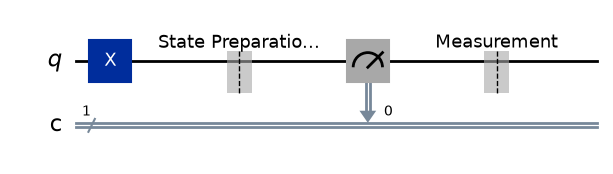

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

# 1. User input
choice = input("Apply X gate? (y/n): ").strip().lower()

if choice not in ["y", "n"]:
    raise ValueError("Enter y or n.")

# 2. Create circuit
q = QuantumRegister(1, 'q')
c = ClassicalRegister(1, 'c')
qc = QuantumCircuit(q, c)

# 3. Prepare state (every qubit starts in |0>)
if choice == "y":
    qc.x(q[0])
    print("X gate applied: |0> -> |1>")
else:
    print("No gate applied: qubit stays in |0>")

qc.barrier(label="State Preparation")

# 4. Statevector before measurement
sv = Statevector(qc)

print("\nStatevector:", np.round(sv.data, 4))
print(f"P(0) = {abs(sv.data[0])**2:.4f}")
print(f"P(1) = {abs(sv.data[1])**2:.4f}")

# 5. Measurement
qc.measure(q[0], c[0])
qc.barrier(label="Measurement")

# 6. Run circuit
result = AerSimulator().run(qc, shots=1024).result()
counts = result.get_counts()

print("\nMeasurement counts (1024 shots):", counts)

# 7. Draw circuit
qc.draw(output='mpl', fold=-1, scale=1.0)

In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("0_1_FirstCircuit.png", dpi=300, bbox_inches="tight")